In [15]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Localizar la raíz del repositorio
ubicacion = Path.cwd().resolve()

raices = [ubicacion, *ubicacion.parents]

raiz = next(
    (
        carpeta for carpeta in raices
        if (carpeta / "F2" / "data" / "processed").is_dir()
    ),
    None
)

assert raiz is not None, "No se encontró la raíz del proyecto"

# Cargar el dataset interpretable de F2
ruta_datos = (
    raiz / "F2" / "data" / "processed"
    / "licitaciones_filtradas_provisional.csv.gz"
)

df_visual = pd.read_csv(ruta_datos)

# Validaciones iniciales
columnas_necesarias = [
    "Estado",
    "EsDesierta",
    "sector",
    "RegionUnidad",
    "Tipo",
    "DiasPublicacionCierre",
    "MontoEstimadoNumerico",
    "Moneda Adquisicion"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in df_visual.columns
]

assert not faltantes, f"Columnas no encontradas: {faltantes}"

print("Raíz del proyecto:", raiz)
print("Dimensiones:", df_visual.shape)
print("\nEstados:")
print(df_visual["Estado"].value_counts(dropna=False))

print("\nMonedas:")
print(df_visual["Moneda Adquisicion"].value_counts(dropna=False))

print("\nValores faltantes por variable:")
print(df_visual[columnas_necesarias].isna().sum())


Raíz del proyecto: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500
Dimensiones: (41607, 18)

Estados:
Estado
Adjudicada                            35622
Desierta (o art. 3 ó 9 Ley 19.886)     5985
Name: count, dtype: int64

Monedas:
Moneda Adquisicion
Peso Chileno         40786
Unidad de Fomento      500
Dolar                  298
Moneda revisar          22
Euro                     1
Name: count, dtype: int64

Valores faltantes por variable:
Estado                      0
EsDesierta                  0
sector                   1539
RegionUnidad                0
Tipo                        0
DiasPublicacionCierre       0
MontoEstimadoNumerico       7
Moneda Adquisicion          0
dtype: int64


In [16]:

# Carpeta de resultados de Fase 4
carpeta_resultados = raiz / "F4" / "resultados"
carpeta_resultados.mkdir(parents=True, exist_ok=True)

print("Carpeta de resultados:", carpeta_resultados)


Carpeta de resultados: C:\Users\Sergio\Desktop\Magister\MCDI500\proyecto-grupo_1-mcdi500\F4\resultados


## 1. Caracterización general de las licitaciones

Se analiza la distribución de las licitaciones adjudicadas y desiertas
correspondientes al primer semestre de 2026.

Esta visualización constituye el contexto inicial del análisis y permite
dimensionar el fenómeno antes de comparar sus características.

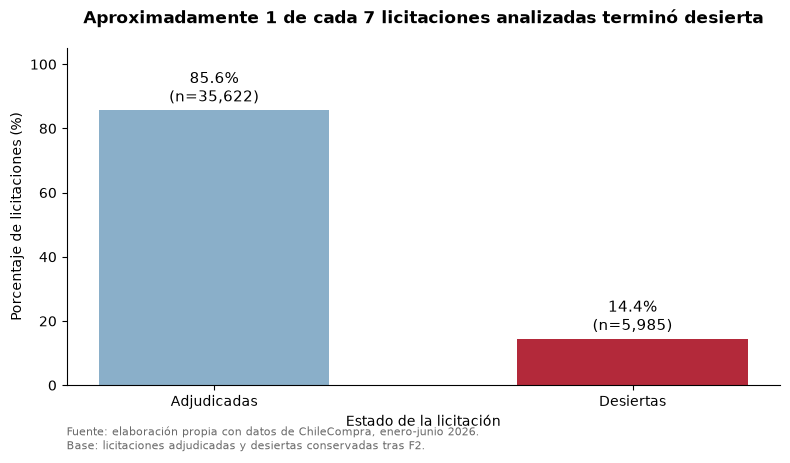

Total de licitaciones: 41607
Total adjudicadas: 35622
Total desiertas: 5985


In [17]:

# Gráfico 1: distribución porcentual por estado

# Validar que la variable objetivo contenga solo valores binarios
assert df_visual["EsDesierta"].notna().all()
assert set(df_visual["EsDesierta"].unique()) == {0, 1}

# Calcular cantidades y porcentajes
conteos = (
    df_visual["EsDesierta"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

porcentajes = conteos / len(df_visual) * 100

etiquetas = ["Adjudicadas", "Desiertas"]
colores = ["#8AAFC9", "#B3293A"]

fig, ax = plt.subplots(figsize=(8, 4.8))

barras = ax.bar(
    etiquetas,
    porcentajes.values,
    color=colores,
    width=0.55
)

# Mostrar porcentaje y cantidad exacta
for barra, porcentaje, cantidad in zip(
    barras, porcentajes.values, conteos.values
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1.2,
        f"{porcentaje:.1f}%\n(n={cantidad:,})",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Aproximadamente 1 de cada 7 licitaciones analizadas terminó desierta",
    fontsize=12,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Porcentaje de licitaciones (%)")
ax.set_xlabel("Estado de la licitación")
ax.set_ylim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.text(
    0, -0.19,
    "Fuente: elaboración propia con datos de ChileCompra, enero-junio 2026.\n"
    "Base: licitaciones adjudicadas y desiertas conservadas tras F2.",
    transform=ax.transAxes,
    fontsize=8,
    color="dimgray"
)

fig.savefig(
    carpeta_resultados / "grafico_1_estados.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

print("Total de licitaciones:", len(df_visual))
print("Total adjudicadas:", conteos.loc[0])
print("Total desiertas:", conteos.loc[1])

assert conteos.sum() == len(df_visual)



### Interpretación del gráfico 1

**¿Qué muestra?**

De las 41.607 licitaciones conservadas después del
preprocesamiento de F2, 35.622 fueron adjudicadas (85,6 %)
y 5.985 fueron declaradas desiertas (14,4 %).

**¿Qué podemos inferir?**

La mayoría de las licitaciones analizadas fueron adjudicadas.
Sin embargo, aproximadamente una de cada siete terminó
desierta, lo que justifica examinar qué características
diferencian ambos grupos.

**¿Qué limitaciones tiene?**

Los porcentajes representan únicamente las licitaciones
incluidas en el conjunto analítico, correspondientes al
primer semestre de 2026 y a los estados seleccionados
en F2. No deben interpretarse como la tasa general de
licitaciones desiertas de todo el sistema de compras
públicas de Chile.

Además, el gráfico no permite identificar las causas
por las cuales una licitación terminó desierta.

**¿Cómo aporta al proyecto?**

Responde al objetivo específico de caracterizar las
licitaciones públicas del período estudiado y establece
el contexto para comparar sus características según
sector, tipo de licitación y plazos de publicación.


## 2. Comparación de licitaciones desiertas por tipo

Se analiza la proporción de licitaciones declaradas desiertas
según el tipo de procedimiento.

La comparación utiliza porcentajes dentro de cada tipo, ya
que las categorías pueden contener cantidades muy diferentes
de licitaciones.

In [18]:

# Gráfico 2: preparación de tasas por tipo de licitación

# Validar los datos de entrada
assert df_visual["Tipo"].notna().all()
assert df_visual["EsDesierta"].isin([0, 1]).all()

# Calcular cantidades y tasas por tipo
resumen_tipo = (
    df_visual
    .groupby("Tipo", dropna=False)
    .agg(
        Total=("EsDesierta", "size"),
        Desiertas=("EsDesierta", "sum")
    )
    .reset_index()
)

resumen_tipo["TasaDesierta"] = (
    resumen_tipo["Desiertas"]
    / resumen_tipo["Total"] * 100
)

resumen_tipo = resumen_tipo.sort_values(
    "TasaDesierta",
    ascending=False
).reset_index(drop=True)

# Validar coherencia del resumen
assert resumen_tipo["Total"].sum() == len(df_visual)
assert resumen_tipo["Desiertas"].sum() == df_visual["EsDesierta"].sum()
assert resumen_tipo["TasaDesierta"].between(0, 100).all()

print("Tasas de licitaciones desiertas por tipo:")
print(
    resumen_tipo.to_string(
        index=False,
        formatters={"TasaDesierta": "{:.2f}%".format}
    )
)

print("\nTipos con menos de 30 licitaciones:")
print(
    resumen_tipo.loc[
        resumen_tipo["Total"] < 30,
        ["Tipo", "Total", "Desiertas", "TasaDesierta"]
    ].to_string(index=False)
)


Tasas de licitaciones desiertas por tipo:
Tipo  Total  Desiertas TasaDesierta
  O2      2          1       50.00%
  E2     74         30       40.54%
  B2    222         72       32.43%
  CO    654        196       29.97%
  I2     42         12       28.57%
  O1    150         30       20.00%
  LQ      6          1       16.67%
  L1   4944        782       15.82%
  LR   1883        292       15.51%
  LE  25396       3559       14.01%
  LP   8218       1010       12.29%
  LS     16          0        0.00%

Tipos con menos de 30 licitaciones:
Tipo  Total  Desiertas  TasaDesierta
  O2      2          1     50.000000
  LQ      6          1     16.666667
  LS     16          0      0.000000


Tipos incluidos: 9
Tipos excluidos de la figura: ['O2', 'LQ', 'LS']
Licitaciones fuera de la figura: 24


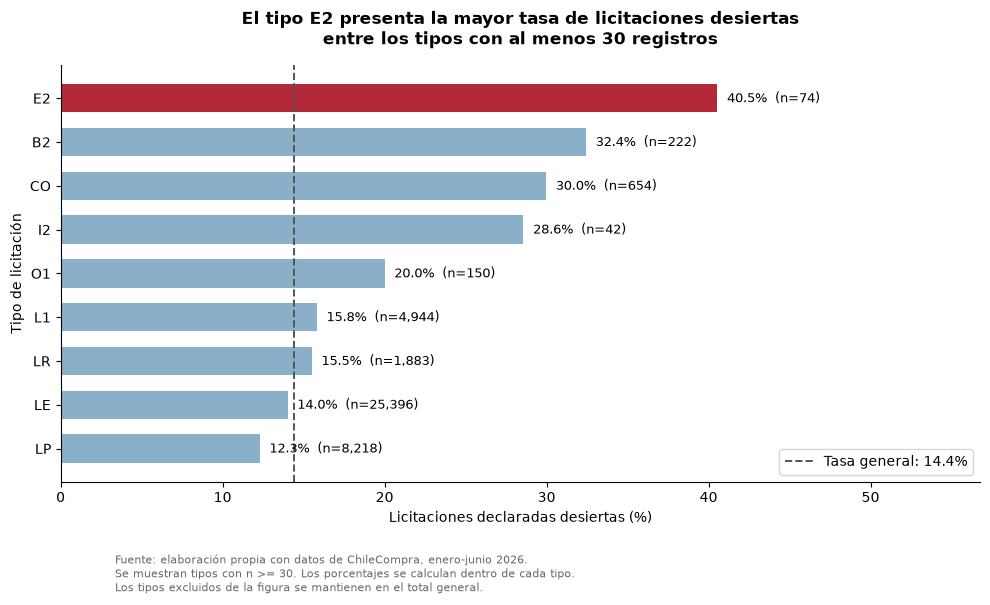

In [19]:

# Gráfico 2: tasa de licitaciones desiertas por tipo

# Umbral descriptivo para evitar destacar grupos muy pequeños
minimo_registros = 30

resumen_grafico = (
    resumen_tipo.loc[
        resumen_tipo["Total"] >= minimo_registros
    ]
    .sort_values("TasaDesierta", ascending=True)
    .copy()
)

# Verificar las categorías incluidas y excluidas
assert not resumen_grafico.empty
assert (resumen_grafico["Total"] >= minimo_registros).all()

excluidos = resumen_tipo.loc[
    resumen_tipo["Total"] < minimo_registros
]

print("Tipos incluidos:", len(resumen_grafico))
print("Tipos excluidos de la figura:", excluidos["Tipo"].tolist())
print("Licitaciones fuera de la figura:", excluidos["Total"].sum())

# Tasa general calculada usando todas las licitaciones
tasa_general = df_visual["EsDesierta"].mean() * 100

# Identificar la mayor tasa entre los tipos incluidos
mayor = resumen_grafico.loc[
    resumen_grafico["TasaDesierta"].idxmax()
]

colores = [
    "#B3293A" if tipo == mayor["Tipo"] else "#8AAFC9"
    for tipo in resumen_grafico["Tipo"]
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    resumen_grafico["Tipo"],
    resumen_grafico["TasaDesierta"],
    color=colores,
    height=0.65
)

# Porcentaje y cantidad de observaciones
for barra, fila in zip(barras, resumen_grafico.itertuples()):
    ax.text(
        barra.get_width() + 0.6,
        barra.get_y() + barra.get_height() / 2,
        f"{fila.TasaDesierta:.1f}%  (n={fila.Total:,})",
        va="center",
        fontsize=9
    )

# Comparación con la tasa general del conjunto
ax.axvline(
    tasa_general,
    color="#555555",
    linestyle="--",
    linewidth=1.4,
    label=f"Tasa general: {tasa_general:.1f}%"
)

ax.set_title(
    f"El tipo {mayor['Tipo']} presenta la mayor tasa "
    "de licitaciones desiertas\n"
    "entre los tipos con al menos 30 registros",
    fontsize=12,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Licitaciones declaradas desiertas (%)")
ax.set_ylabel("Tipo de licitación")
ax.set_xlim(0, resumen_grafico["TasaDesierta"].max() * 1.40)

ax.legend(loc="lower right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.12, 0.005,
    "Fuente: elaboración propia con datos de ChileCompra, enero-junio 2026.\n"
    "Se muestran tipos con n >= 30. Los porcentajes se calculan dentro de cada tipo.\n"
    "Los tipos excluidos de la figura se mantienen en el total general.",
    fontsize=8,
    color="dimgray"
)

fig.savefig(
    carpeta_resultados / "grafico_2_tipos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

# Comprobaciones finales
assert resumen_tipo["Total"].sum() == len(df_visual)
assert resumen_tipo["Desiertas"].sum() == df_visual["EsDesierta"].sum()



### Interpretación del gráfico 2

**¿Qué muestra?**

Se comparan las tasas de licitaciones desiertas según el
tipo de procedimiento. Entre las categorías con al menos
30 registros, E2 presenta la tasa más alta (40,54 %),
seguida de B2 (32,43 %) y CO (29,97 %).

En contraste, LP presenta una tasa de 12,29 %.

**¿Qué podemos inferir?**

Se observan diferencias en la proporción de licitaciones
desiertas entre los distintos tipos de procedimiento.

Estas diferencias justifican examinar el tipo de licitación
como una característica relevante del análisis.

**¿Qué limitaciones tiene?**

Los tipos de licitación tienen tamaños muy distintos.
Por ejemplo, E2 contiene 74 registros y LP contiene 8.218.

Se muestran únicamente categorías con al menos
30 registros. Este umbral es descriptivo y no garantiza
precisión estadística.

Las diferencias observadas no demuestran que el tipo
de licitación cause que un procedimiento termine desierto.

**¿Cómo aporta al proyecto?**

Responde al objetivo de comparar las características
de las licitaciones adjudicadas y desiertas.

Permite identificar tipos de licitación que merecen
un análisis más detallado antes de formular recomendaciones
para los organismos compradores.


## 3. Comparación de los plazos de publicación y cierre

Se analiza la duración entre la publicación y el cierre de las
licitaciones, comparando procedimientos adjudicados y desiertos.

Antes de visualizar los resultados, se revisa la distribución
de los plazos, los posibles valores inconsistentes y los
valores extremos para seleccionar una representación adecuada.

In [20]:

# Diagnóstico previo al gráfico 3

columna_plazo = "DiasPublicacionCierre"

# Preparar una copia sin modificar el dataset original
df_plazos = df_visual[
    ["Estado", "EsDesierta", columna_plazo]
].copy()

df_plazos[columna_plazo] = pd.to_numeric(
    df_plazos[columna_plazo],
    errors="coerce"
)

# Validar las categorías
assert df_plazos["EsDesierta"].isin([0, 1]).all()

# Revisar datos faltantes y posibles inconsistencias
print("Total de registros:", len(df_plazos))
print("Plazos faltantes:", df_plazos[columna_plazo].isna().sum())
print("Plazos negativos:", (df_plazos[columna_plazo] < 0).sum())
print("Plazos iguales a cero:", (df_plazos[columna_plazo] == 0).sum())

print("\nEstadísticas de días por estado:")

resumen_plazos = (
    df_plazos.groupby("Estado")[columna_plazo]
    .agg(
        Registros="count",
        Media="mean",
        Mediana="median",
        Minimo="min",
        Maximo="max"
    )
)

print(resumen_plazos.round(2).to_string())

print("\nPercentiles de los plazos:")

percentiles_plazos = (
    df_plazos.groupby("Estado")[columna_plazo]
    .quantile([0.25, 0.50, 0.75, 0.95, 0.99])
    .unstack()
)

print(percentiles_plazos.round(2).to_string())

# Diagnóstico adicional de valores elevados
print(
    "\nPlazos superiores a 90 días:",
    (df_plazos[columna_plazo] > 90).sum()
)


Total de registros: 41607
Plazos faltantes: 0
Plazos negativos: 0
Plazos iguales a cero: 0

Estadísticas de días por estado:
                                    Registros  Media  Mediana  Minimo  Maximo
Estado                                                                       
Adjudicada                              35622  13.98     12.0     5.0    84.0
Desierta (o art. 3 ó 9 Ley 19.886)       5985  14.60     12.0     5.0    82.0

Percentiles de los plazos:
                                    0.25  0.50  0.75  0.95  0.99
Estado                                                          
Adjudicada                          10.0  12.0  17.0  31.0  36.0
Desierta (o art. 3 ó 9 Ley 19.886)  10.0  12.0  18.0  32.0  42.0

Plazos superiores a 90 días: 0


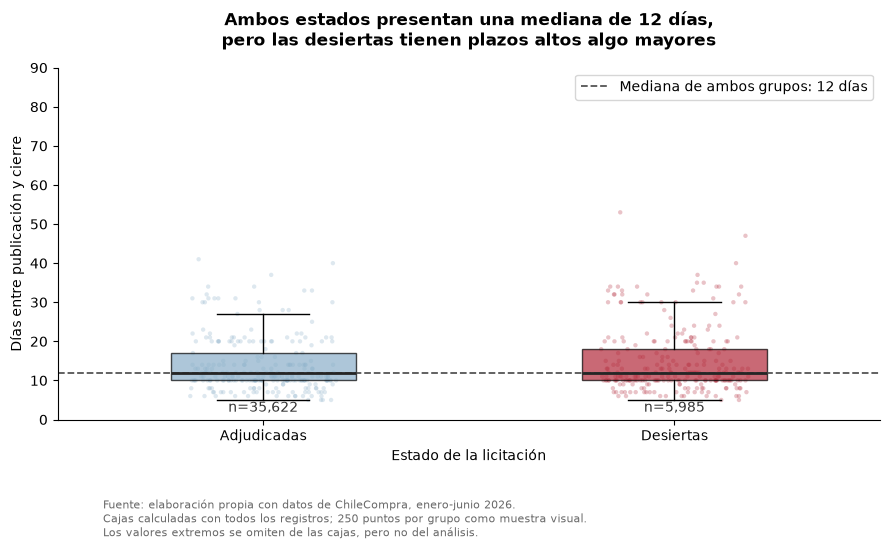

In [21]:

# Gráfico 3: distribución de plazos por estado
# Se utilizan todos los registros para calcular las cajas.
# Los puntos son una muestra visual reproducible.

datos_adjudicadas = df_plazos.loc[
    df_plazos["EsDesierta"] == 0,
    "DiasPublicacionCierre"
].dropna()

datos_desiertas = df_plazos.loc[
    df_plazos["EsDesierta"] == 1,
    "DiasPublicacionCierre"
].dropna()

assert len(datos_adjudicadas) == 35622
assert len(datos_desiertas) == 5985

grupos = [datos_adjudicadas, datos_desiertas]
etiquetas = ["Adjudicadas", "Desiertas"]
colores = ["#8AAFC9", "#B3293A"]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Cajas calculadas utilizando todos los registros
cajas = ax.boxplot(
    grupos,
    tick_labels=etiquetas,
    patch_artist=True,
    widths=0.45,
    showfliers=False,
    medianprops={
        "color": "#252525",
        "linewidth": 2
    }
)

for caja, color in zip(cajas["boxes"], colores):
    caja.set_facecolor(color)
    caja.set_alpha(0.70)

# Muestra de puntos para visualizar observaciones reales
rng = np.random.default_rng(42)

for posicion, (datos, color) in enumerate(
    zip(grupos, colores), start=1
):
    muestra = datos.sample(
        n=min(250, len(datos)),
        random_state=42
    )

    desplazamiento = rng.uniform(
        -0.18, 0.18, len(muestra)
    )

    ax.scatter(
        np.full(len(muestra), posicion) + desplazamiento,
        muestra,
        s=10,
        color=color,
        alpha=0.28,
        edgecolors="none"
    )

# Línea de referencia: ambas medianas son 12 días
ax.axhline(
    12,
    linestyle="--",
    linewidth=1.3,
    color="#555555",
    label="Mediana de ambos grupos: 12 días"
)

ax.set_title(
    "Ambos estados presentan una mediana de 12 días,\n"
    "pero las desiertas tienen plazos altos algo mayores",
    fontsize=12,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Estado de la licitación")
ax.set_ylabel("Días entre publicación y cierre")
ax.set_ylim(0, 90)

ax.legend(loc="upper right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Tamaños reales por grupo
for posicion, datos in enumerate(grupos, start=1):
    ax.text(
        posicion,
        2,
        f"n={len(datos):,}",
        ha="center",
        fontsize=10,
        color="#333333"
    )

fig.text(
    0.12, 0.015,
    "Fuente: elaboración propia con datos de ChileCompra, enero-junio 2026.\n"
    "Cajas calculadas con todos los registros; "
    "250 puntos por grupo como muestra visual.\n"
    "Los valores extremos se omiten de las cajas, "
    "pero no del análisis.",
    fontsize=8,
    color="dimgray"
)

fig.savefig(
    carpeta_resultados / "grafico_3_plazos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

# Validaciones finales
assert datos_adjudicadas.median() == 12
assert datos_desiertas.median() == 12
assert len(datos_adjudicadas) + len(datos_desiertas) == len(df_plazos)



### Interpretación del gráfico 3

**¿Qué muestra?**

Se compara la distribución de los días entre publicación
y cierre de las licitaciones adjudicadas y desiertas.

Ambos grupos presentan una mediana de 12 días.
Las licitaciones adjudicadas registran una media de
13,98 días y las desiertas de 14,60 días.

El percentil 99 alcanza 36 días en las adjudicadas
y 42 días en las desiertas.

**¿Qué podemos inferir?**

No se observa una diferencia en el plazo mediano entre
ambos grupos. Sin embargo, las licitaciones desiertas
presentan valores ligeramente mayores en los percentiles
altos de la distribución.

Por lo tanto, el plazo puede ser una característica
de interés para análisis más detallados, pero las
diferencias descriptivas son limitadas.

**¿Qué limitaciones tiene?**

El gráfico representa asociaciones descriptivas y no
permite establecer causalidad.

Los resultados no controlan diferencias por tipo de
licitación, sector o institución compradora.

Las cajas se calcularon con todos los registros, mientras
que los puntos muestran una muestra reproducible de
250 observaciones por grupo.

**¿Cómo aporta al proyecto?**

Permite comparar una característica temporal de las
licitaciones adjudicadas y desiertas, contribuyendo
al objetivo de identificar patrones asociados al resultado
del procedimiento.


In [22]:

# Verificar las tres figuras exportadas
archivos_figuras = [
    "grafico_1_estados.png",
    "grafico_2_tipos.png",
    "grafico_3_plazos.png"
]

for nombre in archivos_figuras:
    ruta = carpeta_resultados / nombre
    assert ruta.is_file(), f"No se encontró: {nombre}"
    assert ruta.stat().st_size > 0, f"Archivo vacío: {nombre}"

    print(
        f"OK: {nombre} "
        f"({ruta.stat().st_size / 1024:.1f} KB)"
    )

print("\nLas tres figuras fueron exportadas correctamente.")


OK: grafico_1_estados.png (116.6 KB)
OK: grafico_2_tipos.png (199.9 KB)
OK: grafico_3_plazos.png (239.2 KB)

Las tres figuras fueron exportadas correctamente.



## 4. Trazabilidad y evolución del proyecto

El proyecto se desarrolló mediante mejoras progresivas
durante las cuatro fases de la asignatura.

Las correcciones respondieron tanto a observaciones
formativas como a necesidades técnicas identificadas
durante el desarrollo.

| Fase | Situación inicial | Mejora implementada | Evidencia |
|---|---|---|---|
| F1 | Definición inicial del problema | Delimitación de objetivos, alcance y restricciones | `7dda4d6` |
| F2 | Procesamiento principalmente en notebook | Modularización de funciones Python | `e8dc2f3` |
| F2 | Necesidad de mejorar reproducibilidad | Validaciones y exportación de datos | `44df778` |
| F3 | Necesidad de comprobar comportamiento | Pruebas de Factory y Pipeline | `9f9fc60` |
| F3 | Comparaciones de rendimiento limitadas | Mediciones con tamaños crecientes | `5efadea` |
| F3 | Arquitectura poco documentada | Explicación y validación de principios POO | `92c2952` |
| F4 | Falta de resultados visuales integrados | Tres visualizaciones vinculadas a los objetivos | `760a3aa` |

### Impacto de las mejoras

**Modularidad:** las funciones y clases permiten reutilizar
componentes y facilitan el mantenimiento del procesamiento.

**Eficiencia:** las mediciones de F3 respaldan la elección
de operaciones vectorizadas frente a `apply()`.

**Validación:** las pruebas automáticas y las comparaciones
con F2 permiten detectar errores y verificar que las
transformaciones producen resultados coherentes.

**Reproducibilidad:** las dependencias fijadas, los datos
procesados versionados y las instrucciones de ejecución
facilitan reproducir los resultados del proyecto.

**Comunicación:** las visualizaciones de F4 permiten
presentar hallazgos cuantitativos y declarar sus
limitaciones.

### Referencias de trazabilidad

Los commits indicados pueden consultarse en:

https://github.com/IgnacioCardenass/proyecto-grupo_1-mcdi500

El historial detallado se documenta en `changelog.md`.
